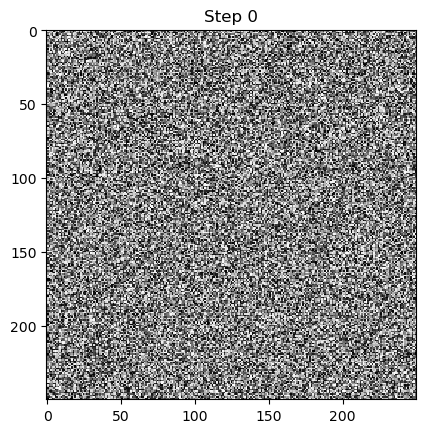

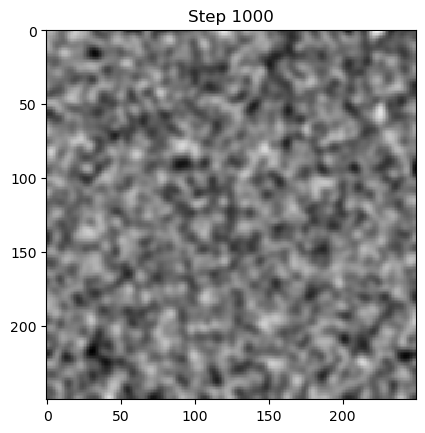

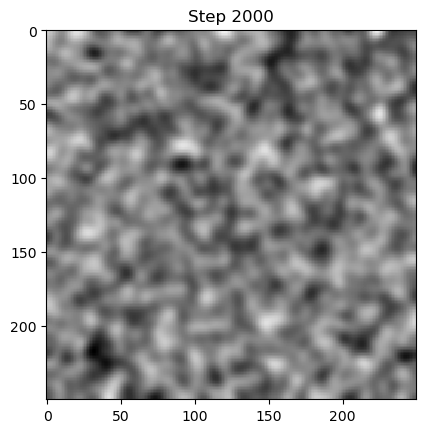

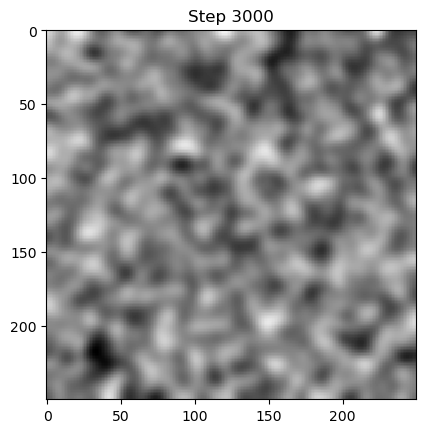

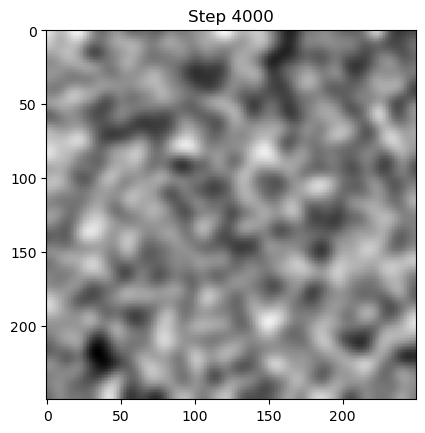

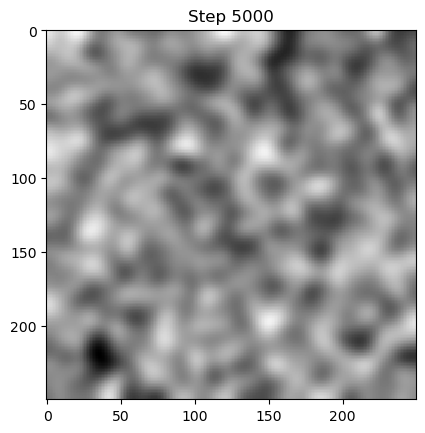

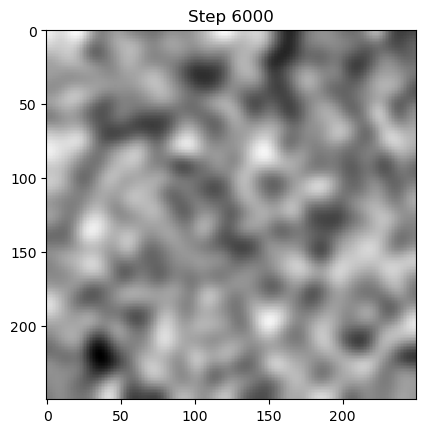

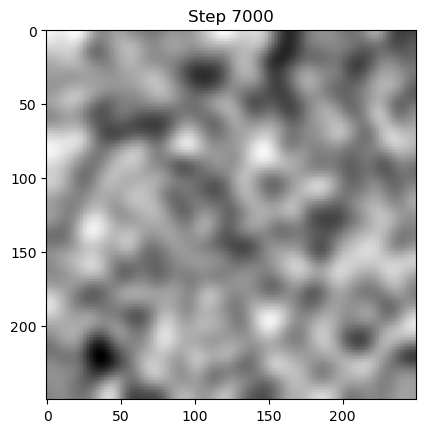

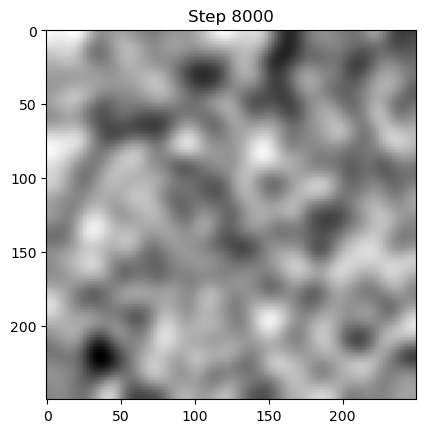

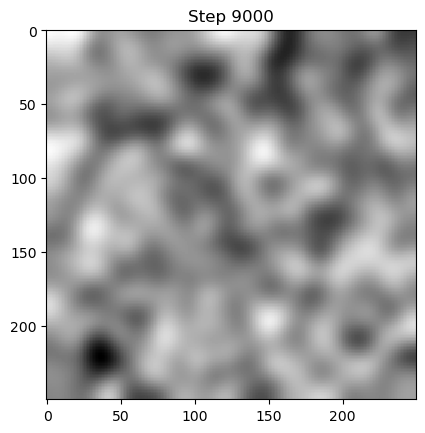

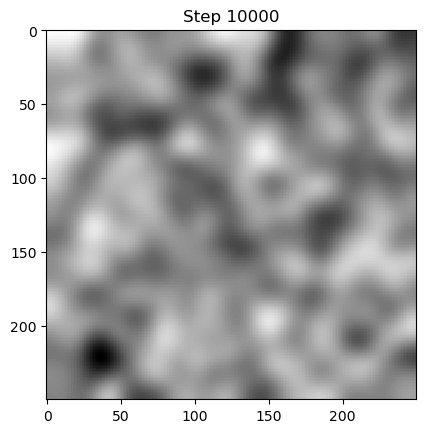

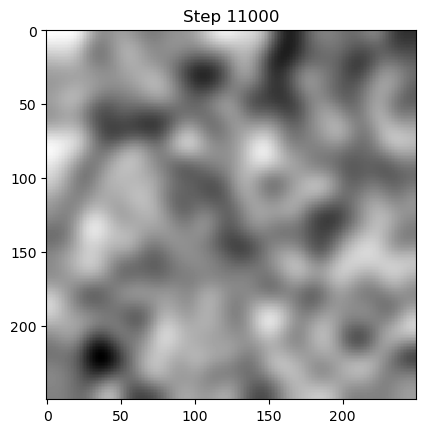

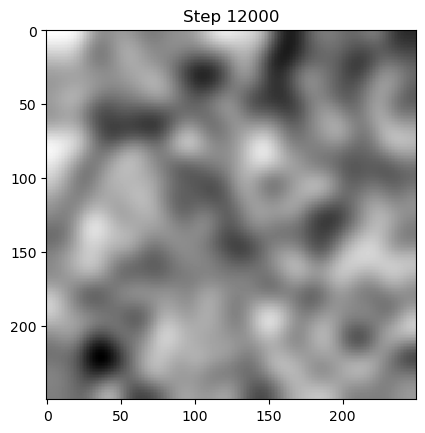

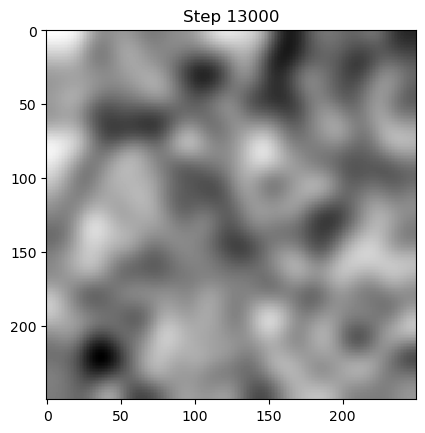

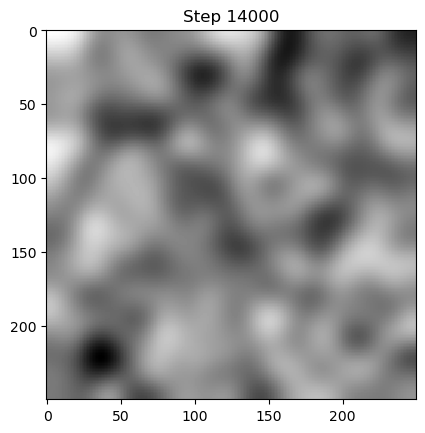

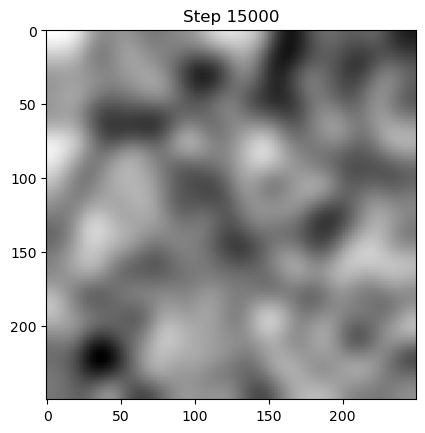

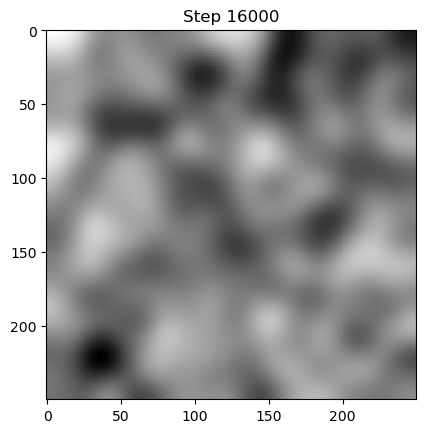

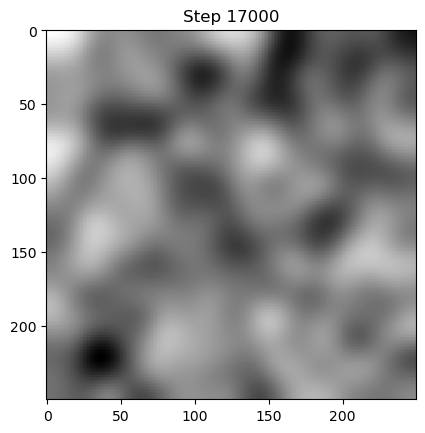

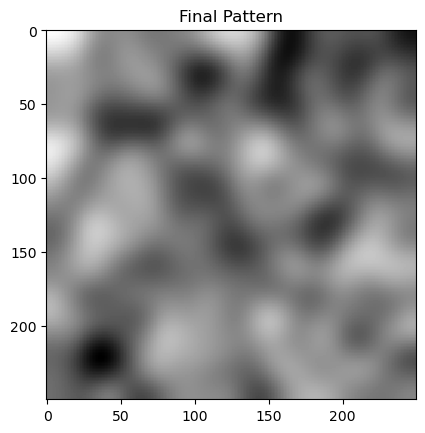

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve

# Parámetros
D = 0.45
delta = 6
alpha = 0.899
beta = -0.91
r2 = 2
r3 = 3.5
gamma = 0.1  # Valor asumido para gamma

# Tamaño del dominio y pasos de tiempo
size = 250
dx = 2. / size
T = 18000
dt = 0.000002  # Reducir el paso de tiempo (es el factor clave!!!!!!)

# Kernel para el operador Laplaciano
laplacian_kernel = np.array([[0.05, 0.2, 0.05],
                             [0.2, -1, 0.2],
                             [0.05, 0.2, 0.05]])

# Condiciones iniciales aleatorias
np.random.seed(0)
u = np.random.rand(size, size)
v = np.random.rand(size, size)


def update(u, v, dt, dx):
    laplacian_u = convolve(u, laplacian_kernel, mode='reflect') / (dx**2)
    laplacian_v = convolve(v, laplacian_kernel, mode='reflect') / (dx**2)

    du_dt = D * laplacian_u + alpha * u + v - r2 * u * v - alpha * r3 * u * v**2
    dv_dt = delta * laplacian_v + gamma * u + beta * v + r2 * u * v - alpha * r3 * u * v**2

   
    u = np.clip(u + du_dt * dt, 0, 1)
    v = np.clip(v + dv_dt * dt, 0, 1)

    return u, v


for t in range(T):
    u, v = update(u, v, dt, dx)

    if t % 1000 == 0:
        plt.imshow(u, cmap='gray', interpolation='nearest')
        plt.title(f"Step {t}")
        plt.show()

plt.imshow(u, cmap='gray', interpolation='nearest')
plt.title("Final Pattern")
plt.show()


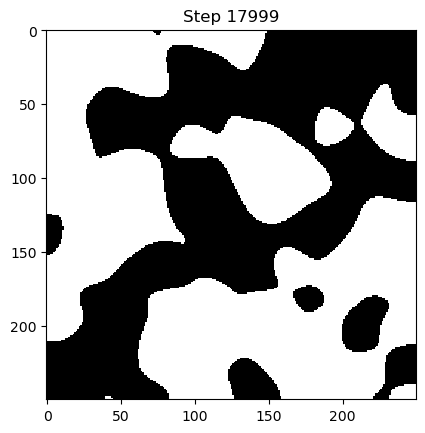

In [26]:


umbral = 0.5  
u_binarizada = np.where(u > umbral, 1, 0)

plt.imshow(u_binarizada, cmap='gray', interpolation='nearest')
plt.title(f"Step {t}")
plt.show()
